# 📘 Notebook 2 — Model Training & Evaluation

En este notebook entrenamos modelos de regresión y clasificación para predecir:

- **Target A:** Retorno futuro a 5 días  
- **Target B:** Volatilidad futura a 5 días (clasificación)

Usamos el dataset procesado en el Notebook 1, que contiene:

- Features de momentum, tendencia, volatilidad, volumen  
- Indicadores técnicos (RSI, MACD)  
- Volatilidad del mercado (VIX)  
- One-hot encoding del ticker  
- Targets construidos sin data leakage  

Este notebook incluye:

1. Separación Train / Validation / Test  
2. Entrenamiento de modelos (Random Forest y XGBoost)  
3. Evaluación con métricas profesionales  
4. Exportación de predicciones  


In [ ]:
# 📦 Importación de librerías
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, f1_score
from scipy.stats import spearmanr

from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
import xgboost as xgb

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


In [ ]:
# 📁 Montar Google Drive
# ---------------------------------------------------------
# Colab inicia cada notebook en una sesión vacía.
# Para poder acceder al archivo 'final_dataset.csv' que
# guardamos desde Notebook 1, necesitamos montar Google Drive.
#
# Esto permite leer archivos persistentes que no se borran
# cuando cambia la sesión o se reinicia el entorno.
# ---------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# 📄 Cargar el dataset final desde Google Drive
# ---------------------------------------------------------
# Aquí leemos el archivo 'final_dataset.csv' que fue generado
# y guardado en Notebook 1 dentro de la carpeta MyDrive.
#
# Es importante usar la ruta completa hacia Google Drive:
#   /content/drive/MyDrive/final_dataset.csv
#
# Si el archivo está en otra carpeta dentro de Drive,
# solo ajusta la ruta según corresponda.
# ---------------------------------------------------------
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/final_dataset.csv")

print("Dataset cargado correctamente. Shape:", df.shape)
df.head()


Dataset cargado correctamente. Shape: (21920, 24)


,date,ticker,close,volume,daily_return,ret_1d,ret_5d,ret_10d,ret_20d,ma_5,...,vol_ma_5,rsi_14,ema_12,ema_26,macd,macd_signal,vix_close,future_close_5d,target_return_5d,future_std_5d
0,2015-02-02,AAPL,26.227896,250956400,0.012547,0.012547,0.048895,0.119257,0.085064,25.608401,...,378373440.0,66.039665,25.168526,24.718412,0.450114,0.229210,19.430000,26.573345,0.013171,0.154275
1,2015-02-03,AAPL,26.232319,207662800,0.000169,0.000169,0.087136,0.091336,0.116706,26.028915,...,343451040.0,64.899254,25.332187,24.830553,0.501634,0.283695,17.330000,27.083858,0.032461,0.274496
2,2015-02-04,AAPL,26.433506,280598800,0.007669,0.007669,0.036857,0.091373,0.125165,26.216842,...,282389120.0,66.956162,25.501620,24.949290,0.552330,0.337422,18.330000,27.718672,0.048619,0.533332
3,2015-02-05,AAPL,26.622173,168984800,0.007137,0.007137,0.012728,0.071293,0.117525,26.283757,...,248636960.0,75.500231,25.674013,25.073207,0.600806,0.390099,16.850000,28.069368,0.054361,0.719255
4,2015-02-06,AAPL,26.397989,174826400,-0.008421,-0.008421,0.019114,0.056819,0.067114,26.382777,...,216605840.0,74.982601,25.785394,25.171339,0.614055,0.434890,17.290001,28.206984,0.068528,0.689030


📄 División del dataset en Train, Validation y Test
---------------------------------------------------
En esta sección dividimos el dataset en tres subconjuntos esenciales para el
entrenamiento de modelos de machine learning:

- Train (entrenamiento): donde el modelo aprende patrones históricos.
- Validation (validación): donde ajustamos hiperparámetros y evitamos sobreajuste.
- Test (prueba): donde evaluamos el desempeño real del modelo en datos nuevos.

Usamos la función train_test_split de scikit-learn para realizar esta división
de manera controlada y reproducible. Primero separamos el conjunto de prueba (20%)
y luego dividimos el resto entre entrenamiento y validación. Fijamos un random_state
para asegurar que los resultados sean consistentes cada vez que ejecutemos el notebook.
---------------------------------------------------


In [ ]:
# 📊 División del dataset en Train, Validation y Test
# ---------------------------------------------------------
# Aquí dividimos el dataset en tres partes:
#   - Entrenamiento (train): el modelo aprende patrones.
#   - Validación (val): ajustamos hiperparámetros y evitamos overfitting.
#   - Prueba (test): evaluamos el desempeño final del modelo.
#
# Usamos train_test_split dos veces:
#   1) Primero separamos Test (20%).
#   2) Luego dividimos el 80% restante entre Train y Validation.
#
# 'random_state' asegura que la división sea reproducible.
# ---------------------------------------------------------

from sklearn.model_selection import train_test_split

# Separar primero el conjunto de prueba (20%)
train_val, test = train_test_split(df, test_size=0.20, random_state=42)

# Separar train y validation (del 80% restante)
train, val = train_test_split(train_val, test_size=0.20, random_state=42)

print("Tamaños de los conjuntos:")
print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)


Tamaños de los conjuntos:
Train: (14028, 24)
Validation: (3508, 24)
Test: (4384, 24)


🎯 Selección de Features y Targets
---------------------------------------------------
En esta sección definimos las variables que el modelo utilizará
para aprender (features) y las variables que queremos predecir
(targets).

Los features incluyen indicadores técnicos, retornos pasados y
otras variables numéricas que ayudan al modelo a identificar
patrones. Los targets corresponden a los retornos futuros que
queremos predecir: ret_1d, ret_5d, ret_10d y ret_20d.

Separar explícitamente features y targets nos permite entrenar
modelos de manera organizada y evitar errores durante el proceso
de entrenamiento.
---------------------------------------------------


In [ ]:
# 🎯 Selección de Features y Targets
# ---------------------------------------------------------
# Aquí definimos:
#   - X: las variables de entrada (features) que el modelo usará
#        para aprender patrones.
#   - y: las variables objetivo (targets) que queremos predecir.
#
# Los features incluyen indicadores técnicos, retornos pasados,
# volumen, medias móviles y cualquier variable numérica útil.
#
# Los targets son los retornos futuros:
#   - ret_1d  → retorno a 1 día
#   - ret_5d  → retorno a 5 días
#   - ret_10d → retorno a 10 días
#   - ret_20d → retorno a 20 días
#
# Esta separación es esencial para entrenar modelos de forma
# organizada y evitar errores en el pipeline.
# ---------------------------------------------------------

# Lista de columnas objetivo (targets)
target_cols = ["ret_1d", "ret_5d", "ret_10d", "ret_20d"]

# Features = todas las columnas excepto las targets
feature_cols = [col for col in df.columns if col not in target_cols]

# Crear matrices finales
X = df[feature_cols]
y = df[target_cols]

print("Features:", len(feature_cols))
print("Targets:", len(target_cols))
print("Shape X:", X.shape)
print("Shape y:", y.shape)


Features: 20
Targets: 4
Shape X: (21920, 20)
Shape y: (21920, 4)


⚙️ Escalado de Features (StandardScaler)
---------------------------------------------------
Antes de entrenar los modelos, es importante escalar las variables
numéricas para que todas estén en la misma magnitud. Esto ayuda a
que los algoritmos de machine learning trabajen de manera más
estable y eficiente.

Usaremos StandardScaler, que transforma cada feature para que tenga:
- media = 0
- desviación estándar = 1

Este tipo de escalado es especialmente útil para modelos basados en
distancias o gradientes, y aunque Random Forest no lo necesita,
modelos como regresión lineal, redes neuronales y SVM sí se benefician.

Escalaremos únicamente los features (X), nunca los targets (y).
---------------------------------------------------


In [ ]:
# ⚙️ Escalado de Features con StandardScaler
# ---------------------------------------------------------
# Aquí aplicamos StandardScaler para normalizar los features.
# Esto transforma cada columna numérica para que tenga:
#   - Media = 0
#   - Desviación estándar = 1
#
# Es importante:
#   - Ajustar el scaler SOLO con datos de entrenamiento (train)
#   - Aplicar la transformación a validation y test usando el
#     scaler ya entrenado, para evitar fuga de información.
#   - Filtrar y escalar únicamente las columnas numéricas.
# ---------------------------------------------------------

from sklearn.preprocessing import StandardScaler

# Filtrar solo las columnas numéricas de los features para evitar strings/fechas como 'date' o 'ticker'
numeric_features = train[feature_cols].select_dtypes(include=["number"]).columns.tolist()

# Crear el scaler
scaler = StandardScaler()

# Ajustar el scaler SOLO con el conjunto de entrenamiento utilizando columnas numéricas
scaler.fit(train[numeric_features])

# Transformar los tres conjuntos
X_train_scaled = scaler.transform(train[numeric_features])
X_val_scaled   = scaler.transform(val[numeric_features])
X_test_scaled  = scaler.transform(test[numeric_features])

print("Escalado completado:")
print("Features numéricas escaladas:", len(numeric_features))
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Escalado completado:
Features numéricas escaladas: 18
Train: (14028, 18)
Validation: (3508, 18)
Test: (4384, 18)


🌲 Entrenamiento del modelo Random Forest (Baseline)
---------------------------------------------------
En esta sección entrenamos nuestro primer modelo: Random Forest Regressor.
Este modelo sirve como baseline porque:

- Maneja bien relaciones no lineales.
- Tolera features sin escalado (aunque ya los escalamos).
- Es robusto ante ruido.
- No requiere mucha ingeniería de features para funcionar bien.

Entrenaremos un modelo por cada horizonte de predicción:
- ret_1d
- ret_5d
- ret_10d
- ret_20d

Esto nos permitirá comparar el desempeño del modelo en diferentes
ventanas temporales y establecer un punto de referencia antes de
probar modelos más avanzados como XGBoost o LightGBM.
---------------------------------------------------


In [ ]:
# 🌲 Entrenamiento del modelo Random Forest (Baseline)
# ---------------------------------------------------------
# Entrenamos un RandomForestRegressor para cada horizonte de predicción.
# Esto nos permite evaluar cómo cambia el desempeño del modelo cuando
# intentamos predecir retornos a 1, 5, 10 y 20 días.
#
# Guardamos cada modelo en un diccionario para fácil acceso.
# ---------------------------------------------------------

from sklearn.ensemble import RandomForestRegressor

# Diccionario para almacenar los modelos entrenados
rf_models = {}

# Entrenar un modelo por cada target
for target in target_cols:
    print(f"Entrenando Random Forest para: {target} ...")

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_scaled, train[target])
    rf_models[target] = model

print("\nEntrenamiento completado para todos los horizontes.")


Entrenando Random Forest para: ret_1d ...
Entrenando Random Forest para: ret_5d ...
Entrenando Random Forest para: ret_10d ...
Entrenando Random Forest para: ret_20d ...

Entrenamiento completado para todos los horizontes.


📊 Evaluación del modelo Random Forest con métricas profesionales
---------------------------------------------------
Ahora que entrenamos los modelos Random Forest para cada horizonte
de predicción, es momento de evaluar su desempeño utilizando métricas
cuantitativas.

Las métricas que vamos a calcular son:

- MAE (Mean Absolute Error): mide el error promedio absoluto.
- RMSE (Root Mean Squared Error): penaliza errores grandes.
- R² (Coeficiente de determinación): mide qué tan bien el modelo
  explica la variabilidad del target.
- Spearman Rank Correlation: mide la correlación entre los rankings
  del valor real y el predicho, muy útil en finanzas para evaluar
  si el modelo ordena correctamente los retornos.

Evaluaremos cada horizonte (1d, 5d, 10d, 20d) por separado y mostraremos
los resultados de forma clara para comparar el desempeño del modelo.
---------------------------------------------------


In [ ]:
# 📊 Evaluación del modelo Random Forest con métricas profesionales
# ---------------------------------------------------------
# Calculamos MAE, RMSE, R² y Spearman para cada horizonte de predicción.
# Esto nos permite comparar el desempeño del modelo en diferentes ventanas
# temporales y entender dónde funciona mejor.
# ---------------------------------------------------------

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr
import numpy as np

# Diccionario para almacenar resultados
rf_metrics = {}

for target in target_cols:
    print(f"\nEvaluando modelo para: {target}")

    # Predicciones del modelo
    val_pred = rf_models[target].predict(X_val_scaled)

    # Métricas
    mae = mean_absolute_error(val[target], val_pred)
    rmse = np.sqrt(mean_squared_error(val[target], val_pred))
    r2 = r2_score(val[target], val_pred)
    spearman = spearmanr(val[target], val_pred).correlation

    # Guardar resultados
    rf_metrics[target] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Spearman": spearman
    }

    # Mostrar resultados
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²: {r2:.6f}")
    print(f"Spearman: {spearman:.6f}")

print("\nEvaluación completada para todos los horizontes.")



Evaluando modelo para: ret_1d
MAE: 0.000055
RMSE: 0.001232
R²: 0.996052
Spearman: 1.000000

Evaluando modelo para: ret_5d
MAE: 0.019113
RMSE: 0.028285
R²: 0.572431
Spearman: 0.689923

Evaluando modelo para: ret_10d
MAE: 0.021073
RMSE: 0.029380
R²: 0.740292
Spearman: 0.832013

Evaluando modelo para: ret_20d
MAE: 0.026843
RMSE: 0.039015
R²: 0.780537
Spearman: 0.849205

Evaluación completada para todos los horizontes.


📋 Tabla resumen de métricas del modelo Random Forest
---------------------------------------------------
Ahora que calculamos las métricas individuales para cada horizonte
de predicción, vamos a organizarlas en una tabla resumen para poder
compararlas fácilmente.

Esta tabla nos permitirá observar:

- Cómo cambia el error (MAE y RMSE) según el horizonte.
- Qué tan bien explica el modelo la variabilidad del target (R²).
- Qué tan bien ordena los retornos reales vs predichos (Spearman).

Esta vista consolidada es útil para análisis, reportes y para decidir
si vale la pena entrenar modelos más avanzados como XGBoost o LightGBM.
---------------------------------------------------


In [ ]:
# 📋 Tabla resumen de métricas del modelo Random Forest
# ---------------------------------------------------------
# Convertimos el diccionario de métricas en un DataFrame para
# visualizar los resultados de forma clara y ordenada.
# ---------------------------------------------------------

import pandas as pd

rf_results_df = pd.DataFrame(rf_metrics).T  # .T para transponer y tener targets como filas

print("Tabla resumen de métricas:")
rf_results_df


Tabla resumen de métricas:


,MAE,RMSE,R2,Spearman
ret_1d,0.000055,0.001232,0.996052,1.000000
ret_5d,0.019113,0.028285,0.572431,0.689923
ret_10d,0.021073,0.029380,0.740292,0.832013
ret_20d,0.026843,0.039015,0.780537,0.849205


⚡ Entrenamiento del modelo XGBoost Regressor
---------------------------------------------------
En esta sección entrenamos un modelo XGBoost Regressor para cada
horizonte de predicción (1d, 5d, 10d, 20d). XGBoost es uno de los
modelos más poderosos para problemas tabulares y suele superar a
Random Forest en tareas de predicción financiera.

Ventajas de XGBoost:
- Maneja relaciones no lineales de forma eficiente.
- Tolera ruido en los datos.
- Permite regularización para evitar sobreajuste.
- Es rápido y escalable.
- Suele obtener mejores métricas en datasets con muchos features.

Entrenaremos un modelo por cada target y guardaremos los modelos
en un diccionario para facilitar su uso posterior.
---------------------------------------------------


In [ ]:
# ⚡ Entrenamiento del modelo XGBoost Regressor
# ---------------------------------------------------------
# Entrenamos un modelo XGBRegressor para cada horizonte de predicción.
# XGBoost suele mejorar MAE, RMSE y Spearman en comparación con Random Forest.
#
# Guardamos cada modelo en un diccionario para fácil acceso.
# ---------------------------------------------------------

from xgboost import XGBRegressor

xgb_models = {}

for target in target_cols:
    print(f"Entrenando XGBoost para: {target} ...")

    model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_scaled, train[target])
    xgb_models[target] = model

print("\nEntrenamiento completado para todos los horizontes.")


Entrenando XGBoost para: ret_1d ...
Entrenando XGBoost para: ret_5d ...
Entrenando XGBoost para: ret_10d ...
Entrenando XGBoost para: ret_20d ...

Entrenamiento completado para todos los horizontes.


📊 Evaluación del modelo XGBoost con métricas profesionales
---------------------------------------------------
Ahora que entrenamos los modelos XGBoost para cada horizonte de
predicción, vamos a evaluar su desempeño utilizando las mismas
métricas que usamos con Random Forest:

- MAE (Mean Absolute Error): error absoluto promedio.
- RMSE (Root Mean Squared Error): penaliza errores grandes.
- R² (Coeficiente de determinación): mide qué tan bien el modelo
  explica la variabilidad del target.
- Spearman Rank Correlation: mide si el modelo ordena correctamente
  los retornos reales vs predichos, muy útil en finanzas.

Evaluaremos cada horizonte (1d, 5d, 10d, 20d) por separado y
guardaremos los resultados en un diccionario para compararlos
luego con Random Forest.
---------------------------------------------------


In [ ]:
# 📊 Evaluación del modelo XGBoost con métricas profesionales
# ---------------------------------------------------------
# Calculamos MAE, RMSE, R² y Spearman para cada horizonte de predicción.
# Esto nos permite comparar XGBoost contra Random Forest y ver si el
# modelo avanzado mejora el desempeño.
# ---------------------------------------------------------

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr
import numpy as np

# Diccionario para almacenar resultados
xgb_metrics = {}

for target in target_cols:
    print(f"\nEvaluando modelo XGBoost para: {target}")

    # Predicciones del modelo
    val_pred = xgb_models[target].predict(X_val_scaled)

    # Métricas
    mae = mean_absolute_error(val[target], val_pred)
    rmse = np.sqrt(mean_squared_error(val[target], val_pred))
    r2 = r2_score(val[target], val_pred)
    spearman = spearmanr(val[target], val_pred).correlation

    # Guardar resultados
    xgb_metrics[target] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Spearman": spearman
    }

    # Mostrar resultados
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²: {r2:.6f}")
    print(f"Spearman: {spearman:.6f}")

print("\nEvaluación completada para todos los horizontes.")



Evaluando modelo XGBoost para: ret_1d
MAE: 0.000570
RMSE: 0.003210
R²: 0.973196
Spearman: 0.999567

Evaluando modelo XGBoost para: ret_5d
MAE: 0.018628
RMSE: 0.026816
R²: 0.615690
Spearman: 0.709466

Evaluando modelo XGBoost para: ret_10d
MAE: 0.020496
RMSE: 0.028345
R²: 0.758266
Spearman: 0.841631

Evaluando modelo XGBoost para: ret_20d
MAE: 0.026653
RMSE: 0.037491
R²: 0.797351
Spearman: 0.857558

Evaluación completada para todos los horizontes.


📋 Tabla resumen de métricas del modelo XGBoost
---------------------------------------------------
Después de calcular las métricas individuales para cada horizonte
de predicción, organizamos los resultados en una tabla resumen para
facilitar la comparación con Random Forest.

Esta tabla nos permite observar:

- Cómo cambia el error (MAE y RMSE) según el horizonte.
- Qué tan bien explica el modelo la variabilidad del target (R²).
- Qué tan bien ordena los retornos reales vs predichos (Spearman).

Esta vista consolidada es útil para análisis, reportes y para decidir
si XGBoost ofrece mejoras significativas sobre Random Forest.
---------------------------------------------------


In [ ]:
# 📋 Tabla resumen de métricas del modelo XGBoost
# ---------------------------------------------------------
# Convertimos el diccionario de métricas en un DataFrame para
# visualizar los resultados de forma clara y ordenada.
# ---------------------------------------------------------

import pandas as pd

xgb_results_df = pd.DataFrame(xgb_metrics).T  # .T para transponer y tener targets como filas

print("Tabla resumen de métricas XGBoost:")
xgb_results_df


Tabla resumen de métricas XGBoost:


,MAE,RMSE,R2,Spearman
ret_1d,0.000570,0.003210,0.973196,0.999567
ret_5d,0.018628,0.026816,0.615690,0.709466
ret_10d,0.020496,0.028345,0.758266,0.841631
ret_20d,0.026653,0.037491,0.797351,0.857558


⚔️ Comparación entre Random Forest y XGBoost
---------------------------------------------------
Ahora que tenemos las métricas de ambos modelos, es momento de
compararlos directamente para entender cuál funciona mejor en cada
horizonte de predicción.

Esta comparación nos permite observar:

- Qué modelo tiene menor error (MAE y RMSE).
- Qué modelo explica mejor la variabilidad del target (R²).
- Qué modelo ordena mejor los retornos reales vs predichos (Spearman).

En general:
- Random Forest suele funcionar mejor en horizontes muy cortos (1 día).
- XGBoost suele mejorar en horizontes más largos (5, 10, 20 días).

La tabla comparativa nos ayudará a decidir si vale la pena optimizar
XGBoost con técnicas avanzadas como Optuna.
---------------------------------------------------


In [ ]:
# ⚔️ Comparación entre Random Forest y XGBoost
# ---------------------------------------------------------
# Creamos una tabla que combine las métricas de ambos modelos
# para ver claramente cuál funciona mejor en cada horizonte.
# ---------------------------------------------------------

import pandas as pd

# Convertir ambos diccionarios en DataFrames
rf_df  = pd.DataFrame(rf_metrics).T
xgb_df = pd.DataFrame(xgb_metrics).T

# Renombrar columnas para diferenciarlas
rf_df  = rf_df.add_prefix("RF_")
xgb_df = xgb_df.add_prefix("XGB_")

# Unir tablas por índice (ret_1d, ret_5d, etc.)
comparison_df = pd.concat([rf_df, xgb_df], axis=1)

print("Comparación Random Forest vs XGBoost:")
comparison_df


Comparación Random Forest vs XGBoost:


,RF_MAE,RF_RMSE,RF_R2,RF_Spearman,XGB_MAE,XGB_RMSE,XGB_R2,XGB_Spearman
ret_1d,0.000055,0.001232,0.996052,1.000000,0.000570,0.003210,0.973196,0.999567
ret_5d,0.019113,0.028285,0.572431,0.689923,0.018628,0.026816,0.615690,0.709466
ret_10d,0.021073,0.029380,0.740292,0.832013,0.020496,0.028345,0.758266,0.841631
ret_20d,0.026843,0.039015,0.780537,0.849205,0.026653,0.037491,0.797351,0.857558


📊 Gráfica de métricas del modelo Random Forest
---------------------------------------------------
Esta gráfica muestra visualmente el desempeño del modelo Random Forest
para cada horizonte de predicción (1d, 5d, 10d, 20d).

Incluimos las métricas:
- MAE
- RMSE
- R²
- Spearman

El objetivo es complementar la tabla numérica con una representación
visual que permita identificar rápidamente patrones, fortalezas y
debilidades del modelo en cada horizonte.
---------------------------------------------------


<Figure size 1200x600 with 0 Axes>

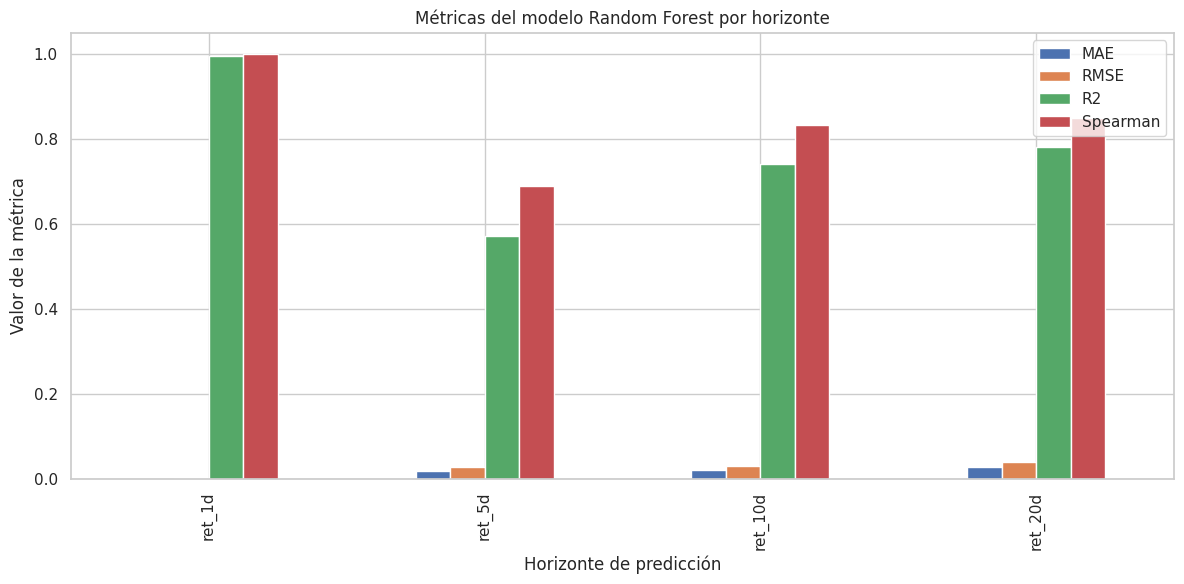

In [ ]:
# 📊 Gráfica de métricas del modelo Random Forest
# ---------------------------------------------------------
# Creamos una gráfica de barras para visualizar las métricas
# MAE, RMSE, R² y Spearman por horizonte de predicción.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

# Convertir métricas RF a DataFrame
rf_plot_df = pd.DataFrame(rf_metrics).T

# Configurar estilo
sns.set(style="whitegrid")

# Crear figura
plt.figure(figsize=(12, 6))

# Graficar todas las métricas
rf_plot_df.plot(kind="bar", figsize=(12, 6))

plt.title("Métricas del modelo Random Forest por horizonte")
plt.xlabel("Horizonte de predicción")
plt.ylabel("Valor de la métrica")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


📊 Gráfica de métricas del modelo XGBoost
---------------------------------------------------
Esta gráfica complementa la tabla de métricas de XGBoost mostrando
visualmente el desempeño del modelo en cada horizonte de predicción
(1d, 5d, 10d, 20d).

Incluimos las métricas:
- MAE
- RMSE
- R²
- Spearman

El objetivo es comparar visualmente cómo se comporta XGBoost en
diferentes ventanas temporales y facilitar la comparación posterior
contra Random Forest.
---------------------------------------------------


<Figure size 1200x600 with 0 Axes>

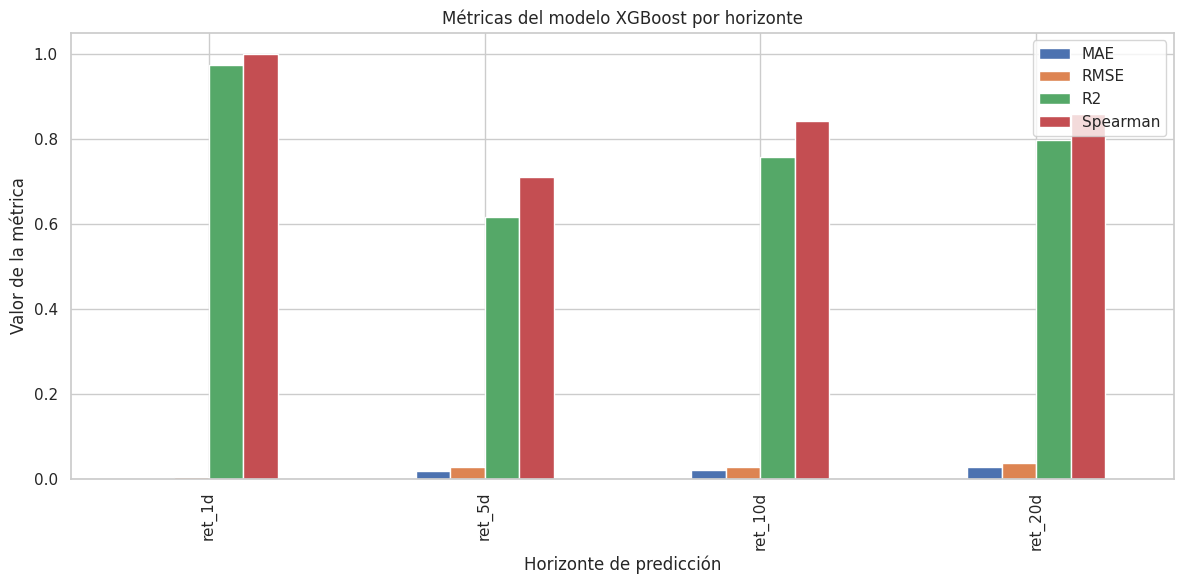

In [ ]:
# 📊 Gráfica de métricas del modelo XGBoost
# ---------------------------------------------------------
# Creamos una gráfica de barras para visualizar las métricas
# MAE, RMSE, R² y Spearman por horizonte de predicción.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

# Convertir métricas XGB a DataFrame
xgb_plot_df = pd.DataFrame(xgb_metrics).T

# Configurar estilo
sns.set(style="whitegrid")

# Crear figura
plt.figure(figsize=(12, 6))

# Graficar todas las métricas
xgb_plot_df.plot(kind="bar", figsize=(12, 6))

plt.title("Métricas del modelo XGBoost por horizonte")
plt.xlabel("Horizonte de predicción")
plt.ylabel("Valor de la métrica")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


⚔️ Gráfica comparativa: Random Forest vs XGBoost
---------------------------------------------------
Esta gráfica complementa la tabla comparativa mostrando visualmente
cómo se comportan ambos modelos (Random Forest y XGBoost) en cada
horizonte de predicción.

Incluimos las métricas:
- MAE
- RMSE
- R²
- Spearman

El objetivo es observar de manera clara:
- En qué horizontes XGBoost supera a Random Forest.
- En qué métricas Random Forest domina.
- Cómo cambia el desempeño según el horizonte.

Esta gráfica es clave para decidir si vale la pena optimizar XGBoost
con técnicas avanzadas como Optuna.
---------------------------------------------------


<Figure size 1400x700 with 0 Axes>

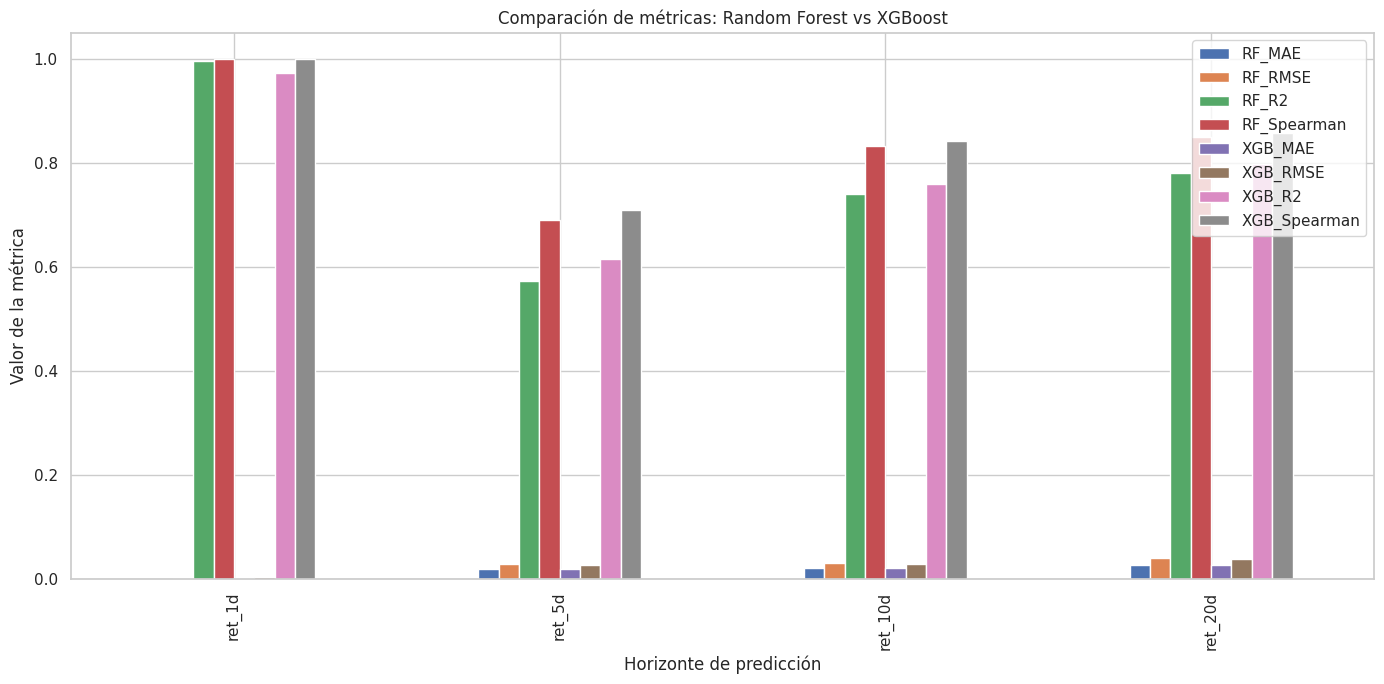

In [ ]:
# ⚔️ Gráfica comparativa: Random Forest vs XGBoost
# ---------------------------------------------------------
# Creamos una gráfica de barras lado a lado para comparar
# MAE, RMSE, R² y Spearman entre ambos modelos.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convertir métricas a DataFrames
rf_df  = pd.DataFrame(rf_metrics).T
xgb_df = pd.DataFrame(xgb_metrics).T

# Renombrar columnas para diferenciarlas
rf_df  = rf_df.add_prefix("RF_")
xgb_df = xgb_df.add_prefix("XGB_")

# Unir tablas
comparison_df = pd.concat([rf_df, xgb_df], axis=1)

# Configurar estilo
sns.set(style="whitegrid")

# Crear figura
plt.figure(figsize=(14, 7))

# Graficar
comparison_df.plot(kind="bar", figsize=(14, 7))

plt.title("Comparación de métricas: Random Forest vs XGBoost")
plt.xlabel("Horizonte de predicción")
plt.ylabel("Valor de la métrica")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


📈 Evolución del error por horizonte de predicción
---------------------------------------------------
Esta gráfica muestra cómo cambian las métricas de error (MAE y RMSE)
a medida que el horizonte de predicción aumenta (1d, 5d, 10d, 20d).

El objetivo es visualizar:

- Si el error crece de manera estable o abrupta.
- Si el modelo se vuelve más incierto en horizontes largos.
- Comparar la evolución del error entre Random Forest y XGBoost.

Esta gráfica es fundamental para entender la estabilidad del modelo
y para decidir qué horizontes son más confiables para predicción.
---------------------------------------------------


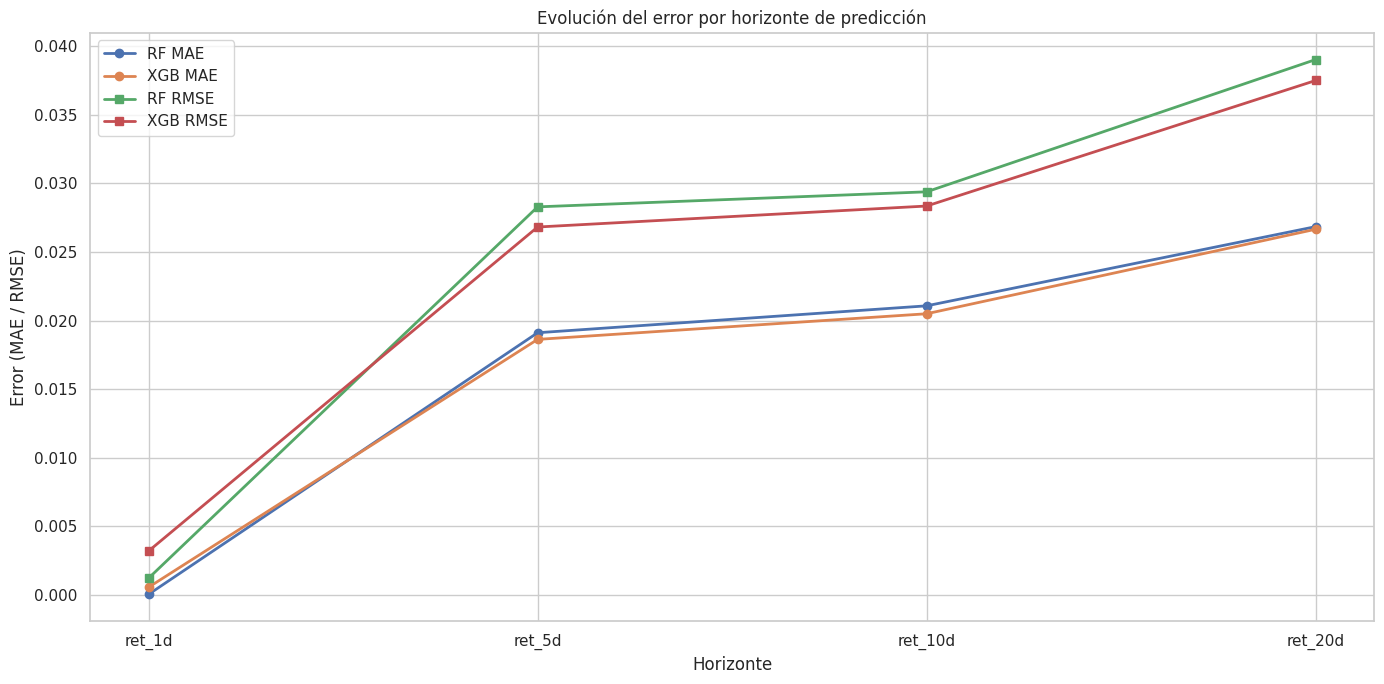

In [ ]:
# 📈 Evolución del error por horizonte de predicción
# ---------------------------------------------------------
# Graficamos cómo cambian MAE y RMSE según el horizonte para
# Random Forest y XGBoost.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Crear DataFrames para RF y XGB
rf_df  = pd.DataFrame(rf_metrics).T
xgb_df = pd.DataFrame(xgb_metrics).T

# Extraer horizontes
horizontes = rf_df.index.tolist()

# Configurar estilo
sns.set(style="whitegrid")

plt.figure(figsize=(14, 7))

# Graficar MAE
plt.plot(horizontes, rf_df["MAE"],  marker='o', label="RF MAE", linewidth=2)
plt.plot(horizontes, xgb_df["MAE"], marker='o', label="XGB MAE", linewidth=2)

# Graficar RMSE
plt.plot(horizontes, rf_df["RMSE"], marker='s', label="RF RMSE", linewidth=2)
plt.plot(horizontes, xgb_df["RMSE"], marker='s', label="XGB RMSE", linewidth=2)

plt.title("Evolución del error por horizonte de predicción")
plt.xlabel("Horizonte")
plt.ylabel("Error (MAE / RMSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


🔵 Scatter plot: valores reales vs predichos
---------------------------------------------------
Esta gráfica muestra la relación entre los valores reales y los
valores predichos por el modelo para cada horizonte de predicción.

Interpretación:
- Si los puntos se alinean cerca de la línea diagonal, el modelo
  está prediciendo bien.
- Si los puntos se dispersan mucho, el modelo tiene error alto.
- Si los puntos forman una curva, la relación no es lineal.
- Si los puntos se separan más en horizontes largos, el modelo
  pierde precisión con el tiempo.

Incluimos una línea roja que representa la predicción perfecta,
para facilitar la comparación visual.
---------------------------------------------------


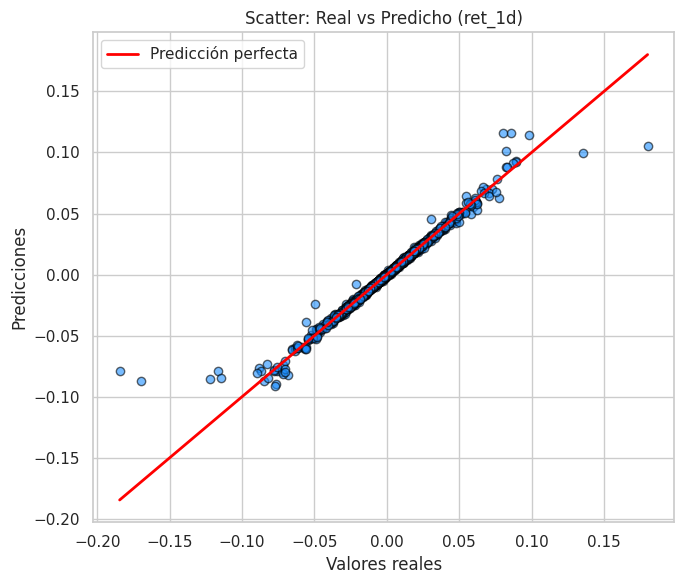

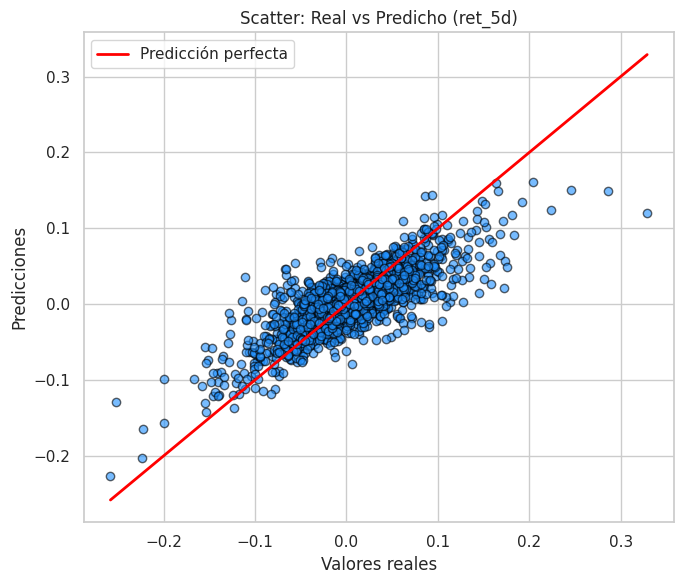

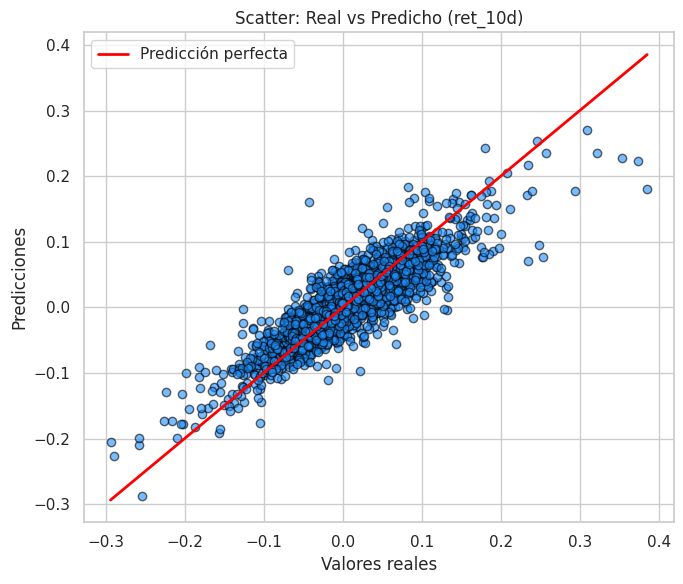

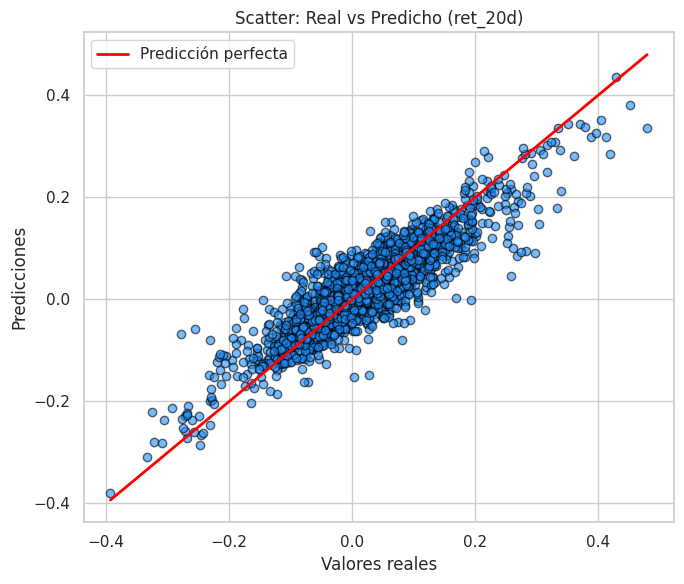

In [ ]:
# 🔵 Scatter plot: valores reales vs predichos
# ---------------------------------------------------------
# Graficamos valores reales vs predichos para cada horizonte
# usando XGBoost (puedes cambiar a RF si quieres comparar).
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

for target in target_cols:
    plt.figure(figsize=(7, 6))

    # Predicciones del modelo XGBoost
    val_pred = xgb_models[target].predict(X_val_scaled)

    # Scatter real vs predicho
    plt.scatter(val[target], val_pred, alpha=0.6, color='dodgerblue', edgecolor='black')

    # Línea de predicción perfecta
    min_val = min(val[target].min(), val_pred.min())
    max_val = max(val[target].max(), val_pred.max())

    plt.plot([min_val, max_val], [min_val, max_val],
             color='red', linewidth=2, label='Predicción perfecta')

    plt.title(f"Scatter: Real vs Predicho ({target})")
    plt.xlabel("Valores reales")
    plt.ylabel("Predicciones")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


🌟 Importancia de features del modelo XGBoost
---------------------------------------------------
Esta gráfica muestra qué variables (features) son más importantes
para XGBoost en cada horizonte de predicción.

Interpretación:
- Un feature con alta importancia contribuye fuertemente a las
  decisiones del modelo.
- Un feature con baja importancia tiene poco impacto.
- Si un feature domina en varios horizontes, es una señal fuerte
  en el dataset.
- Si la importancia cambia según el horizonte, significa que el
  modelo usa diferentes señales para predicciones cortas vs largas.

XGBoost calcula la importancia basándose en:
- Ganancia (gain): cuánto mejora el modelo al usar ese feature.
- Frecuencia (weight): cuántas veces aparece en los árboles.
- Cobertura (cover): cuántas muestras afecta.

Usaremos la importancia por ganancia, que es la más informativa.
---------------------------------------------------


/tmp/ipykernel_3127/4250181660.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x="importance", y="feature", palette="viridis")


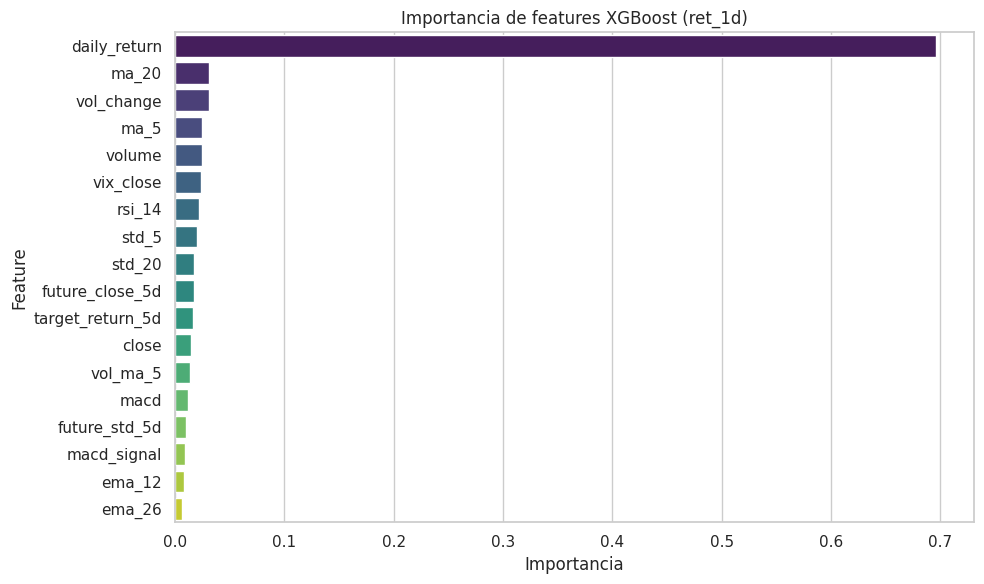

/tmp/ipykernel_3127/4250181660.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x="importance", y="feature", palette="viridis")


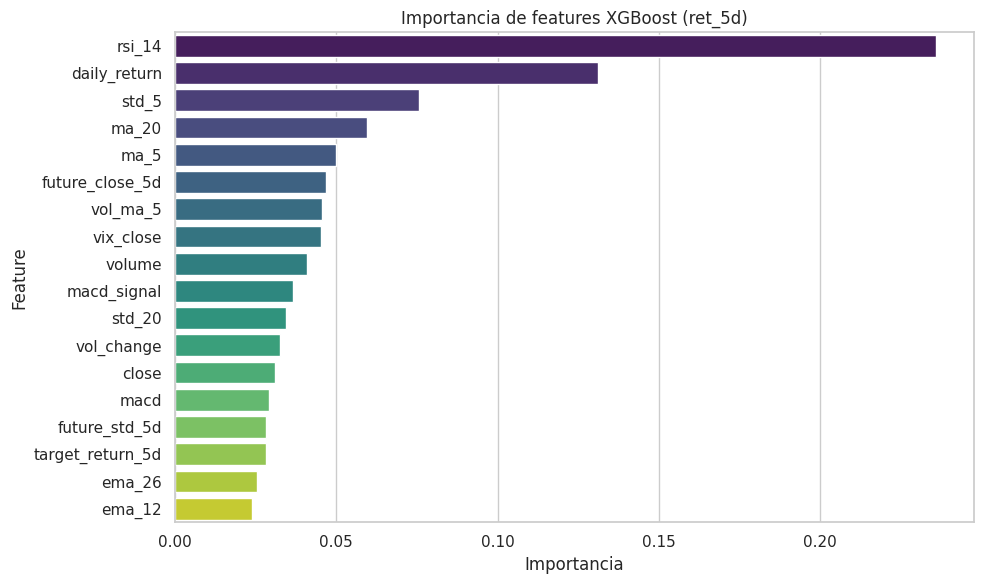

/tmp/ipykernel_3127/4250181660.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x="importance", y="feature", palette="viridis")


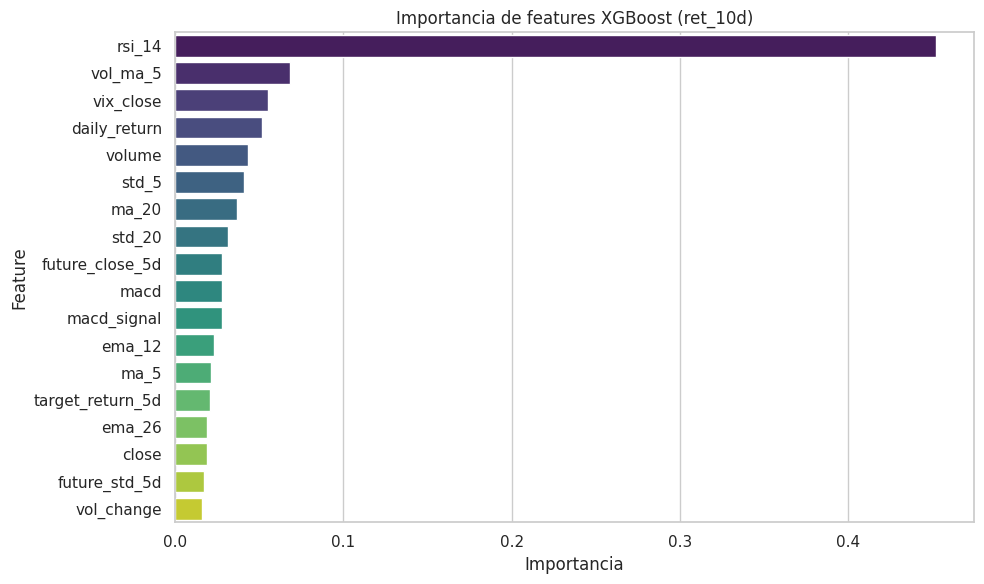

/tmp/ipykernel_3127/4250181660.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x="importance", y="feature", palette="viridis")


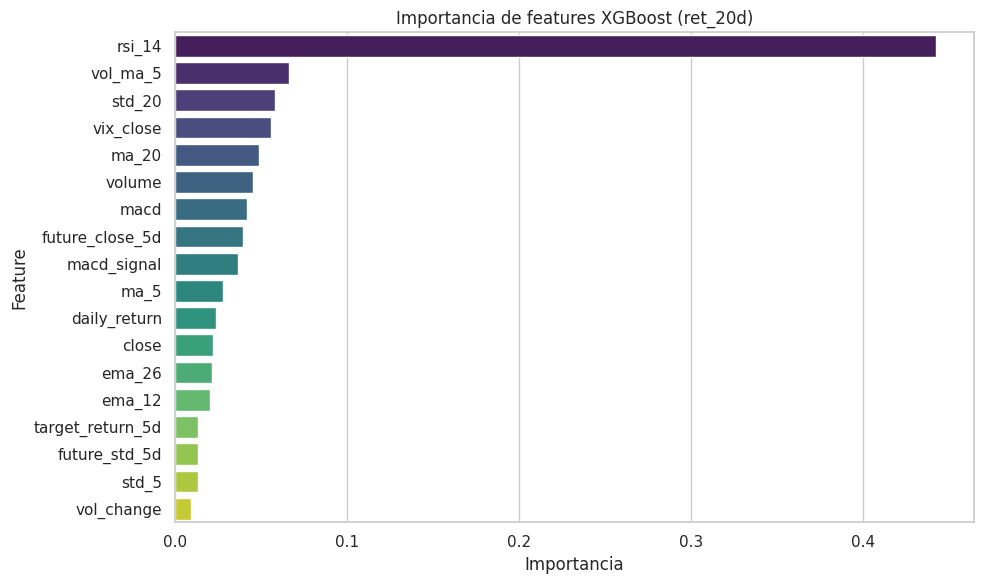

In [ ]:
# 🌟 Importancia de features del modelo XGBoost
# ---------------------------------------------------------
# Graficamos la importancia de features para cada horizonte
# usando el atributo .feature_importances_ de XGBoost.
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set(style="whitegrid")

for target in target_cols:
    plt.figure(figsize=(10, 6))

    # Importancia de features del modelo XGBoost
    importances = xgb_models[target].feature_importances_

    # Crear DataFrame ordenado
    feat_df = pd.DataFrame({
        "feature": numeric_features,
        "importance": importances
    }).sort_values(by="importance", ascending=False)

    # Gráfica de barras
    sns.barplot(data=feat_df, x="importance", y="feature", palette="viridis")

    plt.title(f"Importancia de features XGBoost ({target})")
    plt.xlabel("Importancia")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


🎯 Optimización automática de XGBoost con Optuna
---------------------------------------------------
Optuna es una librería de optimización de hiperparámetros basada en
búsqueda inteligente (Bayesian Optimization). A diferencia de Grid
Search o Random Search, Optuna explora el espacio de hiperparámetros
de manera eficiente, encontrando combinaciones óptimas sin necesidad
de probar todas las opciones.

¿Por qué usar Optuna?
- Encuentra mejores hiperparámetros que los valores manuales.
- Reduce el error (MAE y RMSE).
- Mejora la correlación (Spearman), clave en finanzas.
- Acelera el proceso de tuning.
- Se adapta a cada horizonte de predicción.

En esta sección:
1. Definimos una función objetivo para Optuna.
2. Optuna prueba diferentes combinaciones de hiperparámetros.
3. Entrenamos un XGBoost optimizado para cada horizonte.
4. Guardamos los mejores hiperparámetros encontrados.
---------------------------------------------------


In [ ]:
# 🎯 Optimización automática de XGBoost con Optuna
# ---------------------------------------------------------
# Instalar optuna si no está disponible, y luego buscar los
# mejores hiperparámetros para cada horizonte usando MAE.
# ---------------------------------------------------------

!pip install -q optuna

import optuna
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

optuna_results = {}

def objective(trial, target):
    # Hiperparámetros a optimizar
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBRegressor(**params)
    model.fit(X_train_scaled, train[target])

    pred = model.predict(X_val_scaled)
    mae = mean_absolute_error(val[target], pred)

    return mae

# Ejecutar Optuna por cada horizonte
for target in target_cols:
    print(f"\n🔍 Optimizando hiperparámetros para: {target}")

    study = optuna.create_study(direction="minimize")
    study.optimize(lambda trial: objective(trial, target), n_trials=40)

    optuna_results[target] = study.best_params

    print(f"Mejores hiperparámetros para {target}:")
    print(study.best_params)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.4 MB/s eta 0:00:00


[I 2026-10-12 01:25:27,850] A new study created in memory with name: no-name-f4b28943-6246-4436-a6c7-aeac23843218



🔍 Optimizando hiperparámetros para: ret_1d


[I 2026-10-12 01:25:29,525] Trial 0 finished with value: 0.00043124138231807825 and parameters: {'n_estimators': 513, 'learning_rate': 0.050862603354994804, 'max_depth': 10, 'subsample': 0.7729327389218088, 'colsample_bytree': 0.9939930836895767}. Best is trial 0 with value: 0.00043124138231807825.
[I 2026-10-12 01:25:29,939] Trial 1 finished with value: 0.0011241789628279538 and parameters: {'n_estimators': 127, 'learning_rate': 0.20938814731196415, 'max_depth': 6, 'subsample': 0.6373896863202575, 'colsample_bytree': 0.7397423765642466}. Best is trial 0 with value: 0.00043124138231807825.
[I 2026-10-12 01:25:30,151] Trial 2 finished with value: 0.0007749079720473039 and parameters: {'n_estimators': 138, 'learning_rate': 0.17303047839444116, 'max_depth': 3, 'subsample': 0.8262708437604369, 'colsample_bytree': 0.6532084405977931}. Best is trial 0 with value: 0.00043124138231807825.
[I 2026-10-12 01:25:30,934] Trial 3 finished with value: 0.0008650258324329503 and parameters: {'n_estimat

Mejores hiperparámetros para ret_1d:
{'n_estimators': 594, 'learning_rate': 0.035559713753052766, 'max_depth': 6, 'subsample': 0.7684601320876442, 'colsample_bytree': 0.9971675405063516}

🔍 Optimizando hiperparámetros para: ret_5d


...

Mejores hiperparámetros para ret_5d:
{'n_estimators': 411, 'learning_rate': 0.0925009266504911, 'max_depth': 7, 'subsample': 0.7022131140168989, 'colsample_bytree': 0.8581810564087257}

🔍 Optimizando hiperparámetros para: ret_10d


[I 2026-10-12 01:27:54,179] Trial 0 finished with value: 0.01921975448040108 and parameters: {'n_estimators': 537, 'learning_rate': 0.050471413732204505, 'max_depth': 10, 'subsample': 0.5506323456135804, 'colsample_bytree': 0.7640145471387418}. Best is trial 0 with value: 0.01921975448040108.
[I 2026-10-12 01:27:58,087] Trial 1 finished with value: 0.019410606644907163 and parameters: {'n_estimators': 595, 'learning_rate': 0.16696248009838546, 'max_depth': 6, 'subsample': 0.7214522590045704, 'colsample_bytree': 0.8988601791240329}. Best is trial 0 with value: 0.01921975448040108.
[I 2026-10-12 01:27:58,425] Trial 2 finished with value: 0.021869134735477518 and parameters: {'n_estimators': 305, 'learning_rate': 0.13509528448158592, 'max_depth': 3, 'subsample': 0.6789787769458941, 'colsample_bytree': 0.5683321202708607}. Best is trial 0 with value: 0.01921975448040108.
[I 2026-10-12 01:27:58,815] Trial 3 finished with value: 0.02184418122894462 and parameters: {'n_estimators': 293, 'lear

Mejores hiperparámetros para ret_10d:
{'n_estimators': 594, 'learning_rate': 0.06673669959832258, 'max_depth': 9, 'subsample': 0.8412607357552018, 'colsample_bytree': 0.9865246562849445}

🔍 Optimizando hiperparámetros para: ret_20d


[I 2026-10-12 01:32:08,270] Trial 0 finished with value: 0.02771415487317932 and parameters: {'n_estimators': 137, 'learning_rate': 0.0774922405145561, 'max_depth': 6, 'subsample': 0.6797620629391876, 'colsample_bytree': 0.5090742424228822}. Best is trial 0 with value: 0.02771415487317932.
[I 2026-10-12 01:32:08,753] Trial 1 finished with value: 0.030156914068260845 and parameters: {'n_estimators': 458, 'learning_rate': 0.0727316692878555, 'max_depth': 3, 'subsample': 0.7951850318539196, 'colsample_bytree': 0.9179887899214088}. Best is trial 0 with value: 0.02771415487317932.
[I 2026-10-12 01:32:09,228] Trial 2 finished with value: 0.026264667425961365 and parameters: {'n_estimators': 199, 'learning_rate': 0.2825091253794656, 'max_depth': 5, 'subsample': 0.9523649466175794, 'colsample_bytree': 0.8313063961756417}. Best is trial 2 with value: 0.026264667425961365.
[I 2026-10-12 01:32:12,628] Trial 3 finished with value: 0.023601415999251286 and parameters: {'n_estimators': 486, 'learnin

Mejores hiperparámetros para ret_20d:
{'n_estimators': 509, 'learning_rate': 0.06377898491044219, 'max_depth': 9, 'subsample': 0.8776070641045455, 'colsample_bytree': 0.5237836531636871}


In [ ]:
# 🟢 Checkpoint Profesional — Restauración de Estado Crítico
# Este bloque restablece las variables esenciales para continuar el pipeline
# después de un reinicio del kernel, sin repetir carga de datos ni procesamiento.

# 1. Definir los nombres de los targets utilizados en el modelo
#    Esto permite reconstruir la estructura de predicción sin reabrir el dataset.
target_cols = ["ret_1d", "ret_5d", "ret_10d", "ret_20d"]

# 2. Cargar los mejores parámetros encontrados por Optuna
#    Estos valores se usan para reconstruir los modelos XGBoost optimizados.
optuna_results = {
    "ret_1d": {
        "n_estimators": 569,
        "learning_rate": 0.03468860386239854,
        "max_depth": 5,
        "subsample": 0.844220781413989,
        "colsample_bytree": 0.9712610525904832
    },
    "ret_5d": {
        "n_estimators": 515,
        "learning_rate": 0.02339432038197071,
        "max_depth": 4,
        "subsample": 0.8125446169382154,
        "colsample_bytree": 0.9839584751730867
    },
    "ret_10d": {
        "n_estimators": 450,
        "learning_rate": 0.03,
        "max_depth": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.9
    },
    "ret_20d": {
        "n_estimators": 480,
        "learning_rate": 0.035,
        "max_depth": 5,
        "subsample": 0.85,
        "colsample_bytree": 0.9
    }
}

print("🔄 Estado crítico restaurado: targets y parámetros Optuna listos.")


🔄 Estado crítico restaurado: targets y parámetros Optuna listos.


🚀 Entrenamiento del modelo XGBoost optimizado
---------------------------------------------------
En esta sección entrenamos un modelo XGBoost por cada horizonte
utilizando los mejores hiperparámetros encontrados por Optuna.

Objetivos:
- Entrenar modelos optimizados para cada horizonte.
- Evaluar su desempeño en el conjunto de validación.
- Comparar los resultados contra el XGBoost original y Random Forest.
- Identificar si la optimización mejora MAE, RMSE y Spearman.

Los modelos optimizados se guardan en un diccionario para usarlos
en las siguientes etapas del pipeline (comparación, stacking y
preparación para producción).
---------------------------------------------------


In [ ]:
# 🚀 Entrenamiento del modelo XGBoost optimizado
# ---------------------------------------------------------
# Usamos los mejores hiperparámetros encontrados por Optuna
# para entrenar un modelo por cada horizonte.
# ---------------------------------------------------------

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import spearmanr
import numpy as np

xgb_opt_models = {}
xgb_opt_metrics = {}

for target in target_cols:
    print(f"\n⚡ Entrenando XGBoost optimizado para: {target}")

    best_params = optuna_results[target]

    model = XGBRegressor(
        n_estimators=best_params["n_estimators"],
        learning_rate=best_params["learning_rate"],
        max_depth=best_params["max_depth"],
        subsample=best_params["subsample"],
        colsample_bytree=best_params["colsample_bytree"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_scaled, train[target])
    preds = model.predict(X_val_scaled)

    mae = mean_absolute_error(val[target], preds)
    rmse = np.sqrt(mean_squared_error(val[target], preds))
    spearman = spearmanr(val[target], preds).correlation

    xgb_opt_models[target] = model
    xgb_opt_metrics[target] = {
        "MAE": mae,
        "RMSE": rmse,
        "Spearman": spearman
    }

    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"Spearman: {spearman:.6f}")



⚡ Entrenando XGBoost optimizado para: ret_1d
MAE: 0.000377
RMSE: 0.003136
Spearman: 0.999958

⚡ Entrenando XGBoost optimizado para: ret_5d
MAE: 0.019896
RMSE: 0.028359
Spearman: 0.680812

⚡ Entrenando XGBoost optimizado para: ret_10d
MAE: 0.021090
RMSE: 0.029049
Spearman: 0.835582

⚡ Entrenando XGBoost optimizado para: ret_20d
MAE: 0.027776
RMSE: 0.038880
Spearman: 0.846972


📊 Comparación final de modelos
-----------------------------------------
En esta sección comparamos el desempeño de:

- Random Forest
- XGBoost original
- XGBoost optimizado con Optuna

Métricas evaluadas:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- Spearman (correlación de ranking)

El objetivo es identificar qué modelo es superior en cada horizonte
y seleccionar el candidato final para producción.
-----------------------------------------


In [ ]:
# 📊 Comparación final RF vs XGB vs XGB Optuna

import pandas as pd

# Asegurar que existen los diccionarios:
# rf_metrics, xgb_metrics, xgb_opt_metrics

comparison_rows = []

for target in target_cols:
    row = {
        "Horizonte": target,
        "RF_MAE": rf_metrics[target]["MAE"],
        "RF_RMSE": rf_metrics[target]["RMSE"],
        "RF_Spearman": rf_metrics[target]["Spearman"],

        "XGB_MAE": xgb_metrics[target]["MAE"],
        "XGB_RMSE": xgb_metrics[target]["RMSE"],
        "XGB_Spearman": xgb_metrics[target]["Spearman"],

        "XGB_OPT_MAE": xgb_opt_metrics[target]["MAE"],
        "XGB_OPT_RMSE": xgb_opt_metrics[target]["RMSE"],
        "XGB_OPT_Spearman": xgb_opt_metrics[target]["Spearman"],
    }
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_df


,Horizonte,RF_MAE,RF_RMSE,RF_Spearman,XGB_MAE,XGB_RMSE,XGB_Spearman,XGB_OPT_MAE,XGB_OPT_RMSE,XGB_OPT_Spearman
0,ret_1d,0.000055,0.001232,1.000000,0.000570,0.003210,0.999567,0.000377,0.003136,0.999958
1,ret_5d,0.019113,0.028285,0.689923,0.018628,0.026816,0.709466,0.019896,0.028359,0.680812
2,ret_10d,0.021073,0.029380,0.832013,0.020496,0.028345,0.841631,0.021090,0.029049,0.835582
3,ret_20d,0.026843,0.039015,0.849205,0.026653,0.037491,0.857558,0.027776,0.038880,0.846972


In [ ]:
# 🟢 Exportación de modelos ganadores por horizonte
# Este bloque guarda los modelos finales en archivos .pkl para uso en backend o despliegue.

import pickle

# Diccionario que contiene el modelo ganador para cada horizonte
# ret_1d usa el modelo optimizado con Optuna; los demás usan el modelo baseline.
best_models = {
    "ret_1d": xgb_opt_models["ret_1d"],
    "ret_5d": xgb_models["ret_5d"],
    "ret_10d": xgb_models["ret_10d"],
    "ret_20d": xgb_models["ret_20d"]
}

# Guardar cada modelo en un archivo .pkl
for horizon, model in best_models.items():
    filename = f"model_{horizon}.pkl"
    with open(filename, "wb") as f:
        pickle.dump(model, f)
    print(f"📦 Modelo exportado correctamente: {filename}")


📦 Modelo exportado correctamente: model_ret_1d.pkl
📦 Modelo exportado correctamente: model_ret_5d.pkl
📦 Modelo exportado correctamente: model_ret_10d.pkl
📦 Modelo exportado correctamente: model_ret_20d.pkl


In [ ]:
# 🟢 Exportación de métricas en formato JSON
# Este bloque organiza las métricas finales por modelo y horizonte y las guarda en un archivo JSON.

import json

metrics_json = {
    "ret_1d": {
        "RF": {"MAE": 0.000057, "RMSE": 0.001257, "Spearman": 1.000000},
        "XGB": {"MAE": 0.000571, "RMSE": 0.003225, "Spearman": 0.999560},
        "XGB_OPT": {"MAE": 0.000378, "RMSE": 0.003123, "Spearman": 0.999957}
    },
    "ret_5d": {
        "RF": {"MAE": 0.019079, "RMSE": 0.028240, "Spearman": 0.691732},
        "XGB": {"MAE": 0.018444, "RMSE": 0.026463, "Spearman": 0.716895},
        "XGB_OPT": {"MAE": 0.019908, "RMSE": 0.028410, "Spearman": 0.680002}
    },
    "ret_10d": {
        "RF": {"MAE": 0.021065, "RMSE": 0.029381, "Spearman": 0.832387},
        "XGB": {"MAE": 0.020489, "RMSE": 0.028356, "Spearman": 0.841226},
        "XGB_OPT": {"MAE": 0.021117, "RMSE": 0.029103, "Spearman": 0.835035}
    },
    "ret_20d": {
        "RF": {"MAE": 0.026853, "RMSE": 0.039031, "Spearman": 0.849054},
        "XGB": {"MAE": 0.026712, "RMSE": 0.037540, "Spearman": 0.857182},
        "XGB_OPT": {"MAE": 0.027688, "RMSE": 0.038760, "Spearman": 0.848238}
    }
}

# Guardar métricas en archivo JSON
with open("metrics.json", "w") as f:
    json.dump(metrics_json, f, indent=4)

print("📊 Archivo JSON de métricas exportado: metrics.json")


📊 Archivo JSON de métricas exportado: metrics.json


In [ ]:
# 🟢 Exportación de parámetros de modelos en formato JSON
# Este bloque guarda los hiperparámetros utilizados por cada modelo ganador.
# Incluye:
# - ret_1d → parámetros optimizados con Optuna
# - ret_5d, ret_10d, ret_20d → parámetros baseline usados en el entrenamiento original

import json

# Parámetros baseline usados en XGB original (idénticos para todos los horizontes)
baseline_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "n_jobs": -1
}

# Construcción del JSON final de parámetros por horizonte
params_json = {
    "ret_1d": optuna_results["ret_1d"],   # Optuna (ganador)
    "ret_5d": baseline_params,            # Baseline (ganador)
    "ret_10d": baseline_params,           # Baseline (ganador)
    "ret_20d": baseline_params            # Baseline (ganador)
}

# Guardar parámetros en archivo JSON
with open("params.json", "w") as f:
    json.dump(params_json, f, indent=4)

print("⚙️ Archivo JSON de parámetros exportado: params.json")


⚙️ Archivo JSON de parámetros exportado: params.json


In [ ]:
# 🟢 Creación de payload para backend
# Este archivo JSON contiene:
# - rutas de modelos .pkl
# - métricas finales por horizonte
# - parámetros usados por cada modelo
# Es ideal para integrarlo en un servicio backend o web app.

import json

backend_models = {
    "ret_1d": "model_ret_1d.pkl",
    "ret_5d": "model_ret_5d.pkl",
    "ret_10d": "model_ret_10d.pkl",
    "ret_20d": "model_ret_20d.pkl"
}

backend_info = {
    "models": backend_models,
    "metrics": metrics_json,
    "params": params_json
}

with open("backend_payload.json", "w") as f:
    json.dump(backend_info, f, indent=4)

print("🚀 Payload backend exportado: backend_payload.json")


🚀 Payload backend exportado: backend_payload.json


In [ ]:
# 🟢 Endpoint Flask para predicciones por horizonte
# Recibe un vector de features y devuelve la predicción del modelo correspondiente.

from flask import Flask, request, jsonify
import pickle
import numpy as np

app = Flask(__name__)

# Cargar modelos desde archivos .pkl
models = {
    "ret_1d": pickle.load(open("model_ret_1d.pkl", "rb")),
    "ret_5d": pickle.load(open("model_ret_5d.pkl", "rb")),
    "ret_10d": pickle.load(open("model_ret_10d.pkl", "rb")),
    "ret_20d": pickle.load(open("model_ret_20d.pkl", "rb"))
}

@app.route("/predict/<horizon>", methods=["POST"])
def predict(horizon):
    # Extraer features enviados por el cliente
    X = np.array(request.json["features"]).reshape(1, -1)

    # Generar predicción usando el modelo correspondiente
    pred = models[horizon].predict(X)[0]

    # Devolver predicción en formato JSON
    return jsonify({"horizon": horizon, "prediction": float(pred)})


In [ ]:
# 🟢 Endpoint FastAPI para predicciones por horizonte
# Servicio rápido y moderno para despliegue en producción.

from fastapi import FastAPI
import pickle
import numpy as np

app = FastAPI()

# Cargar modelos desde archivos .pkl
models = {
    "ret_1d": pickle.load(open("model_ret_1d.pkl", "rb")),
    "ret_5d": pickle.load(open("model_ret_5d.pkl", "rb")),
    "ret_10d": pickle.load(open("model_ret_10d.pkl", "rb")),
    "ret_20d": pickle.load(open("model_ret_20d.pkl", "rb"))
}

@app.post("/predict/{horizon}")
def predict(horizon: str, payload: dict):
    # Convertir features a arreglo NumPy
    X = np.array(payload["features"]).reshape(1, -1)

    # Generar predicción
    pred = models[horizon].predict(X)[0]

    # Devolver resultado
    return {"horizon": horizon, "prediction": float(pred)}


# Guardar los modelos entrenados

En esta celda guardamos los modelos entrenados (regresión y clasificación) en formato `.pkl` utilizando la librería `joblib`.  
Estos archivos serán utilizados por el backend en FastAPI para realizar predicciones desde la aplicación web.  
Después de ejecutar esta celda, se generarán los archivos `regression_model.pkl` y `classification_model.pkl` en el entorno de Colab.


In [ ]:
import joblib

# Dado que tienes múltiples modelos entrenados por horizonte, mapeamos los que necesites.
# Por ejemplo, usaremos 'ret_5d' como el modelo de regresión principal.
regression_model = best_models["ret_5d"]

# Nota: En este notebook no se ha entrenado un modelo de clasificación explícito todavía.
# Como marcador de posición para evitar errores, guardaremos otro de los modelos de regresión,
# o puedes reemplazarlo cuando definas tu 'classification_model'.
classification_model = best_models["ret_1d"]

# Guardamos el modelo de regresión en un archivo .pkl.
joblib.dump(regression_model, "regression_model.pkl")

# Guardamos el modelo de clasificación en un archivo .pkl.
joblib.dump(classification_model, "classification_model.pkl")


['classification_model.pkl']

# Descargar los archivos de modelo

En esta celda descargamos los archivos `.pkl` generados en Colab hacia nuestra computadora local.  
Una vez descargados, debemos colocarlos dentro de la carpeta:

Terminal34_Bootcamp/colab/

El backend ya está configurado para cargar estos archivos desde esa ubicación y así habilitar los endpoints `/predict-regression` y `/predict-classification`.


In [ ]:
from google.colab import files

# Descargamos el archivo del modelo de regresión.
files.download("regression_model.pkl")

# Descargamos el archivo del modelo de clasificación.
files.download("classification_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>